# 03 - Transformation (KDD stage 3) - real data
Turns the cleaned daily table into a supervised learning problem.

**Task:** given what is known at the end of day *t*, predict whether day *t+1* will be a
**heavy-rain day**, i.e. at least `HEAVY_RAIN_MM` mm of rain.

### Be clear about the target
The two files contain no recorded flood events, so the target is **heavy rainfall**, not floods.
It is a rainfall-hazard proxy, useful as a precursor signal for flood warnings, and it must not be
reported as flood-prediction accuracy. The repo's own `docs/REAL_DATA_GUIDE.md` makes the same point.
The target is the *next day's* rain and the inputs are today's and earlier values, so the model forecasts
rather than restating its own inputs.

`HEAVY_RAIN_MM = 10` is a project choice, set so the 12 months of data hold enough positive days to learn
from (about 7% of days). A 20 mm threshold would leave only about 24 positive days across both regions, too few to evaluate.

In [1]:
import sys
from pathlib import Path


def _find_helpers():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base, base / "notebooks" / "real_data"):
            if (cand / "weather_data.py").is_file():
                return cand
    raise SystemExit("weather_data.py not found. Open this notebook from inside the repository.")


sys.path.insert(0, str(_find_helpers()))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import weather_data as wd

ROOT = wd.find_root()
OUT = wd.out_dir(ROOT)
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
COLORS = {"KZN-ETHEKWINI": "#2a6fbb", "MP-EHLANZENI": "#d9822b"}
LABEL = {rid: s["label"] for rid, s in wd.STATIONS.items()}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

HEAVY_RAIN_MM = 10.0
API_DECAY = 0.85  # antecedent precipitation index decay, same value the backend uses

df = pd.read_csv(OUT / "weather_clean.csv", parse_dates=["date"]).sort_values(["region_id", "date"])
elevation = {rid: m["elevation_m"] for rid, m in json.loads(
    (OUT / "weather_selected.meta.json").read_text())["stations"].items()}

## 1. Feature engineering (per region, using only information up to day *t*)
| Feature | Meaning |
|---|---|
| `rainfall_mm`, `rain_lag1..3` | rain today and 1-3 days earlier |
| `rain_3d`, `rain_7d` | rolling rain totals (soil wetness proxy) |
| `api` | antecedent precipitation index: `api_t = 0.85 * api_(t-1) + rain_t` |
| `temperature_c`, `humidity_pct`, `pressure_hpa`, `wind_ms` | today's weather |
| `dpressure_1d`, `dpressure_3d` | pressure change over 1 and 3 days (falling pressure precedes storms) |
| `doy_sin`, `doy_cos` | time of year, encoded cyclically |
| `elevation_m` | station elevation from the file metadata (9 m vs 660 m) |

In [2]:
def make_features(g: pd.DataFrame, rid: str) -> pd.DataFrame:
    g = g.sort_values("date").reset_index(drop=True).copy()
    rain = g["rainfall_mm"].to_numpy()
    api = np.zeros(len(g))
    api[0] = rain[0]
    for t in range(1, len(g)):
        api[t] = API_DECAY * api[t - 1] + rain[t]
    g["api"] = api
    for k in (1, 2, 3):
        g[f"rain_lag{k}"] = g["rainfall_mm"].shift(k)
    g["rain_3d"] = g["rainfall_mm"].rolling(3).sum()
    g["rain_7d"] = g["rainfall_mm"].rolling(7).sum()
    g["dpressure_1d"] = g["pressure_hpa"].diff(1)
    g["dpressure_3d"] = g["pressure_hpa"].diff(3)
    doy = g["date"].dt.dayofyear.to_numpy()
    g["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    g["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    g["elevation_m"] = elevation[rid]
    g["target_rain_next_mm"] = g["rainfall_mm"].shift(-1)  # tomorrow's rain
    g["y"] = (g["target_rain_next_mm"] >= HEAVY_RAIN_MM).astype(float)
    g.loc[g["target_rain_next_mm"].isna(), "y"] = np.nan  # last day has no "tomorrow"
    return g


FEATURES = ["rainfall_mm", "rain_lag1", "rain_lag2", "rain_lag3", "rain_3d", "rain_7d", "api",
            "temperature_c", "humidity_pct", "pressure_hpa", "wind_ms",
            "dpressure_1d", "dpressure_3d", "doy_sin", "doy_cos", "elevation_m"]

feat = pd.concat([make_features(g, rid) for rid, g in df.groupby("region_id")], ignore_index=True)
before = len(feat)
feat = feat.dropna(subset=FEATURES + ["y"]).reset_index(drop=True)  # drops the first 7 days (no history) and last day
print(f"rows: {before} -> {len(feat)} (dropped {before - len(feat)}: warm-up days with no history, final day with no 'tomorrow')")
feat["y"] = feat["y"].astype(int)
feat[["region_id", "date"] + FEATURES + ["y"]].head()

rows: 790 -> 776 (dropped 14: warm-up days with no history, final day with no 'tomorrow')


,region_id,date,rainfall_mm,rain_lag1,rain_lag2,rain_lag3,rain_3d,rain_7d,api,temperature_c,humidity_pct,pressure_hpa,wind_ms,dpressure_1d,dpressure_3d,doy_sin,doy_cos,elevation_m,y
0,KZN-ETHEKWINI,2021-06-07,0.0,0.0,0.0,1.2,0.0,55.0,25.993439,16.2,70,1025.9,7.722,-4.0,-3.5,0.411054,-0.911611,9.0,0
1,KZN-ETHEKWINI,2021-06-08,0.0,0.0,0.0,0.0,0.0,52.4,22.094423,16.7,65,1023.6,4.750,-2.3,-6.7,0.395312,-0.918547,9.0,0
2,KZN-ETHEKWINI,2021-06-09,0.0,0.0,0.0,0.0,0.0,21.1,18.780260,16.4,73,1024.0,4.889,0.4,-5.9,0.379453,-0.925211,9.0,0
3,KZN-ETHEKWINI,2021-06-10,0.0,0.0,0.0,0.0,0.0,1.2,15.963221,16.0,85,1023.8,4.028,-0.2,-2.1,0.363482,-0.931601,9.0,0
4,KZN-ETHEKWINI,2021-06-11,0.0,0.0,0.0,0.0,0.0,0.0,13.568738,16.7,81,1021.5,4.583,-2.3,-2.1,0.347403,-0.937716,9.0,0


## 2. The target

In [3]:
tgt = feat.groupby("region_id")["y"].agg(["size", "sum", "mean"]).rename(
    columns={"size": "days", "sum": "heavy_rain_days", "mean": "share"}).rename(index=LABEL)
tgt.loc["All"] = [len(feat), feat["y"].sum(), feat["y"].mean()]
tgt["share"] = (tgt["share"] * 100).round(1).astype(str) + " %"
tgt

,days,heavy_rain_days,share
region_id,,,
Durban (KwaZulu-Natal),388.0,32.0,8.2 %
Mbombela (Mpumalanga),388.0,23.0,5.9 %
All,776.0,55.0,7.1 %


About 1 day in 14 is a heavy-rain day. That imbalance matters: a model that always answers "no heavy rain"
would be right about 93% of the time and be useless. Notebook 04 reports precision, recall, F1 and
AUC instead of accuracy alone.

## 3. Chronological train / validation / test split
A random shuffle would put neighbouring days (which share weather) on both sides of the split and leak
information. Instead the timeline is cut by date: the first 60% of days train the models, the next 20% tune the
decision threshold, and the final 20% is touched once for reporting. The cut dates are fixed by this rule
before any model is trained.

In [4]:
days = np.sort(feat["date"].unique())
T_VAL = pd.Timestamp(days[int(len(days) * 0.6)])
T_TEST = pd.Timestamp(days[int(len(days) * 0.8)])
feat["split"] = np.where(feat["date"] < T_VAL, "train", np.where(feat["date"] < T_TEST, "val", "test"))

split_tbl = feat.groupby("split").agg(
    first_day=("date", "min"), last_day=("date", "max"), rows=("y", "size"), heavy_rain_days=("y", "sum"))
split_tbl = split_tbl.loc[["train", "val", "test"]]
split_tbl["first_day"] = split_tbl["first_day"].dt.date
split_tbl["last_day"] = split_tbl["last_day"].dt.date
print(f"validation starts {T_VAL.date()}, test starts {T_TEST.date()}")
split_tbl

validation starts 2022-01-25, test starts 2022-04-13


,first_day,last_day,rows,heavy_rain_days
split,,,,
train,2021-06-07,2022-01-24,464,30
val,2022-01-25,2022-04-12,156,17
test,2022-04-13,2022-06-29,156,8


**Warning:** the test period holds only a handful of heavy-rain days (see `heavy_rain_days` above), so
any single test score is noisy. Notebook 04 therefore adds a walk-forward evaluation over the whole year and
bootstrap intervals, and does not rely on the test split alone.

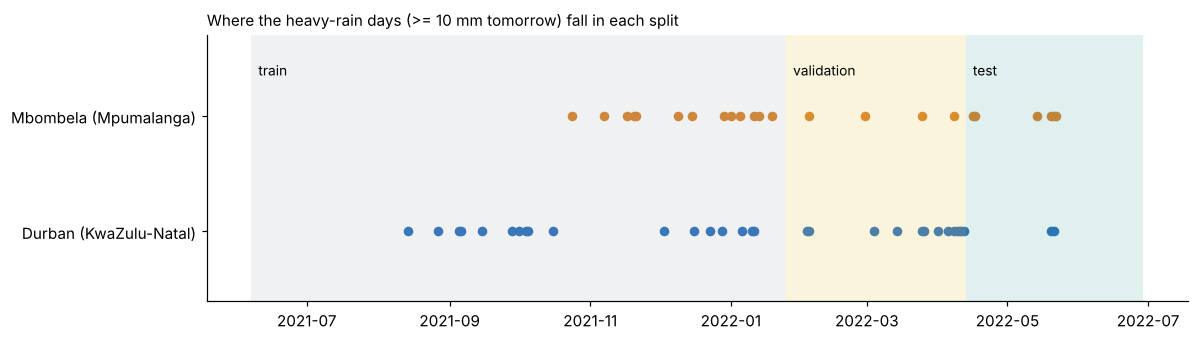

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for rid, g in feat.groupby("region_id"):
    ev = g[g["y"] == 1]
    ax.scatter(ev["date"], [LABEL[rid]] * len(ev), s=28, color=COLORS[rid], label=f"heavy-rain day ({LABEL[rid]})")
ax.axvspan(feat["date"].min(), T_VAL, color="#9aa5b1", alpha=0.15, lw=0)
ax.axvspan(T_VAL, T_TEST, color="#e8c547", alpha=0.18, lw=0)
ax.axvspan(T_TEST, feat["date"].max(), color="#2a9d8f", alpha=0.15, lw=0)
for x, name in ((feat["date"].min(), "train"), (T_VAL, "validation"), (T_TEST, "test")):
    ax.text(x + pd.Timedelta(days=3), 1.35, name, fontsize=9)
ax.set_ylim(-0.6, 1.7)
ax.set_title(f"Where the heavy-rain days (>= {HEAVY_RAIN_MM:.0f} mm tomorrow) fall in each split", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "03_split_timeline.png", dpi=130)
plt.show()

## 4. Scaling
Logistic regression needs standardised inputs. The scaler is **fitted on the training split only** and
applied unchanged to validation and test (fitting on all data would leak the future's statistics).
Tree models do not need scaling but use the same table.

In [6]:
train = feat["split"] == "train"
mean = feat.loc[train, FEATURES].mean()
std = feat.loc[train, FEATURES].std().replace(0, 1.0)
scaler = {"features": FEATURES, "mean": mean.round(6).to_dict(), "std": std.round(6).to_dict()}
pd.DataFrame({"train_mean": mean, "train_std": std}).round(3)

,train_mean,train_std
rainfall_mm,2.379,5.587
rain_lag1,2.380,5.587
rain_lag2,2.376,5.588
rain_lag3,2.364,5.587
rain_3d,7.135,11.183
rain_7d,16.781,19.365
api,15.690,15.750
temperature_c,19.260,3.544
humidity_pct,69.944,13.950
pressure_hpa,1018.761,6.303


## 5. Save the modelling table

In [7]:
keep = ["region_id", "date", "split", "y", "target_rain_next_mm"] + FEATURES
feat[keep].to_csv(OUT / "weather_features.csv", index=False)
(OUT / "weather_features.meta.json").write_text(json.dumps({
    "data_kind": "real", "target": f"rain on day t+1 >= {HEAVY_RAIN_MM} mm (rainfall proxy, NOT recorded floods)",
    "heavy_rain_mm": HEAVY_RAIN_MM, "api_decay": API_DECAY, "val_start": str(T_VAL.date()),
    "test_start": str(T_TEST.date()), "scaler": scaler,
    "rows": {k: int(v) for k, v in feat["split"].value_counts().items()},
    "positives": {k: int(v) for k, v in feat.groupby("split")["y"].sum().items()},
}, indent=2), encoding="utf-8")
print("saved", (OUT / "weather_features.csv").relative_to(ROOT), feat[keep].shape)

saved notebooks/real_data/outputs/weather_features.csv (776, 21)
